# 2D Synchrotron XRD Integration and Rietveld Refinement of FCC Nickel (`Ni.tiff`)

This notebook documents the complete diffraction data reduction, phase matching, and structural Rietveld refinement workflow for **`Ni.tiff`** using **`easyxrd`** (following the conventions of [`MehmetTopsakal/easyXRD_examples`](https://github.com/MehmetTopsakal/easyXRD_examples)):

1. **Detector & Calibration Inspection**: Characterizing the raw 2D area-detector image (`Ni.tiff`), bad-pixel/beamstop mask (`_mask.edf`), and `pyFAI` geometry (`_calibration.poni`, $\lambda = 0.1799\text{ }\text{\AA}$).
2. **2D Cake & 1D Radial Integration**: Converting the 2D diffraction image into an azimuthal cake (`i2d`) and 1D radial profile (`i1d`) with propagated Poisson uncertainties, and exporting 1D `.qxye` / `.xye` profiles.
3. **Phase Matching & Screening**: Screening and indexing experimental Bragg reflections against FCC Nickel (`Ni.cif`, space group $Fm\bar{3}m$, No. 225).
4. **Instrument Resolution Analysis (`_instrument_parameters.gpx`)**: Reading GSAS-II instrument parameters calibrated on $\text{LaB}_6$ and analyzing Caglioti/Lorentzian peak-width behavior across $q$.
5. **Progressive Le Bail $\rightarrow$ Rietveld Refinement**: Refining Chebyshev background, cubic unit cell $a$, crystallite domain size, microstrain, cubic spherical-harmonic preferred orientation, and Ni $U_{\text{iso}}$, followed by a simultaneous full-matrix polish.
6. **Direct Unmodified GPX Cross-Check**: Verifying consistency on the full-ring/mid-$q$ region ($q \in [1.0, 7.4]\text{ }\text{\AA}^{-1}$) using `instprm_from_gpx="_instrument_parameters.gpx"` verbatim.
7. **Diagnostics, Summary & Exports**: Inspecting linear/residual fits, peak zooms, $R_{wp}$ convergence history, refined crystallographic parameters with standard uncertainties, and exporting `.gpx` and `.nc` artifacts.


## 1. Environment Setup and Raw Detector / Mask Inspection

We begin by configuring `easyxrd` logging, verifying package versions, and inspecting the raw Dexela 2923 detector image (`Ni.tiff`), pixel mask (`_mask.edf`), and `pyFAI` calibration geometry (`_calibration.poni`).


In [1]:
import warnings
from pathlib import Path

import fabio
import matplotlib.pyplot as plt
import numpy as np
import pyFAI

import easyxrd
from easyxrd import configure_logging, exrd, show_config
from easyxrd.results import format_value_with_su
from easyxrd.utils import load_gsas_module

%matplotlib inline
plt.rcParams["figure.constrained_layout.use"] = True

configure_logging()
show_config()


easyXRD environment and configurations
Platform            : Linux-7.1.5-76070105-generic-x86_64-with-glibc2.39
python              : 3.14.8
executable          : /home/mt/mpixi/.pixi/envs/default/bin/python
easyxrd             : 2026.11.4
pyFAI               : 2026.9.0
fabio               : 2026.6.0
numpy               : 2.5.4
scipy               : 1.18.1
pymatgen            : 2026.9.24
GSAS-II             : 2.0.0
GSASII_module       : /home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII/GSASIIscriptable.py
verbose             : False
radial_unit         : q
plot_figsize        : (8, 6)
plot_i2d_robust     : True
plot_i1d_ylogscale  : True
plot_i2d_logscale   : True
plot_site_str_x     : 0.3
plot_site_str_y     : 0.8
plot_close          : False
plot_show_wt_fractions: False
plot_show_phase_profiles: True
plot_normalized_residuals: False
i1d_plotter_xlabel  : True
i1d_plotter_return_da: False
i1d_plotter_title_str: 
i1d_plotter_ncol    : 1
i1d_plotter_show_Ybkg_old: Fa

Detector            : Dexela 2923 (3888 x 3072 pixels, 75 x 75 um)
Sample-detector dist: 599.497 mm
PONI1, PONI2        : 140.657 mm, 99.346 mm
X-ray wavelength    : 0.1799 A (68.92 keV)
Raw image stats     : dtype=float32, min=-145.75, median=12.52, max=6903.61
Masked pixels       : 54,514 / 11,943,936 (0.46%)


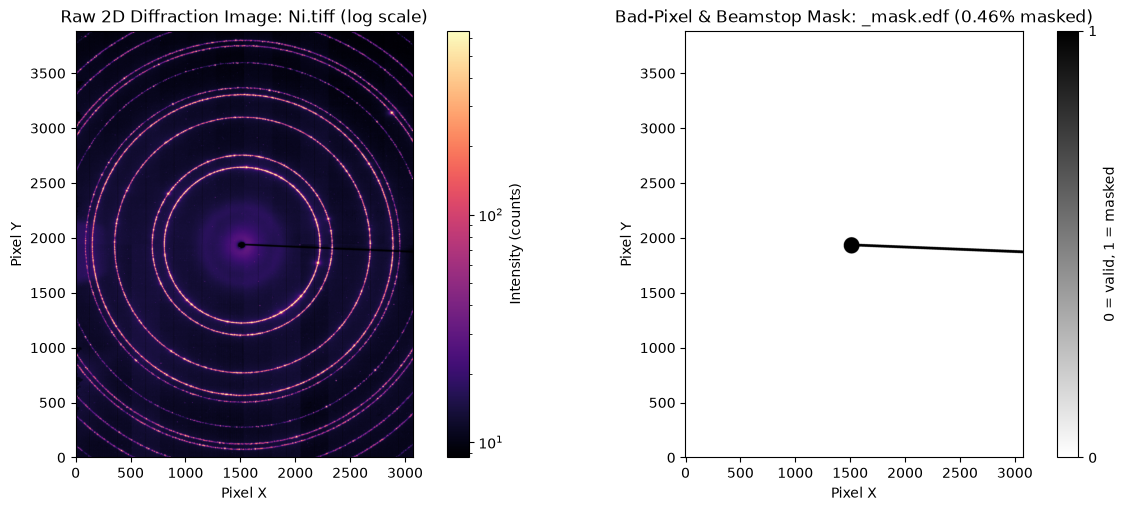

In [2]:
poni_file = "_calibration.poni"
mask_file = "_mask.edf"
tiff_file = "Ni.tiff"
cif_file = "Ni.cif"
inst_gpx_file = "_instrument_parameters.gpx"

ai = pyFAI.load(poni_file)
raw_img = fabio.open(tiff_file).data
mask_arr = fabio.open(mask_file).data.astype(bool)

wavelength_angstrom = ai.wavelength * 1e10
energy_kev = 12.39841984 / wavelength_angstrom

print(f"Detector            : {ai.detector.name} ({raw_img.shape[0]} x {raw_img.shape[1]} pixels, "
      f"{ai.detector.pixel1*1e6:.0f} x {ai.detector.pixel2*1e6:.0f} um)")
print(f"Sample-detector dist: {ai.dist*1e3:.3f} mm")
print(f"PONI1, PONI2        : {ai.poni1*1e3:.3f} mm, {ai.poni2*1e3:.3f} mm")
print(f"X-ray wavelength    : {wavelength_angstrom:.4f} A ({energy_kev:.2f} keV)")
print(f"Raw image stats     : dtype={raw_img.dtype}, min={raw_img.min():.2f}, "
      f"median={np.median(raw_img):.2f}, max={raw_img.max():.2f}")
print(f"Masked pixels       : {mask_arr.sum():,} / {mask_arr.size:,} ({100*mask_arr.mean():.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
vmin, vmax = np.percentile(raw_img[~mask_arr], [1, 99.7])
im0 = axes[0].imshow(np.clip(raw_img, max(vmin, 1.0), vmax), cmap="magma", norm="log", origin="lower")
axes[0].set_title("Raw 2D Diffraction Image: Ni.tiff (log scale)")
axes[0].set_xlabel("Pixel X")
axes[0].set_ylabel("Pixel Y")
plt.colorbar(im0, ax=axes[0], fraction=0.046, label="Intensity (counts)")

im1 = axes[1].imshow(mask_arr, cmap="gray_r", origin="lower", vmin=0, vmax=1)
axes[1].set_title(f"Bad-Pixel & Beamstop Mask: _mask.edf ({100*mask_arr.mean():.2f}% masked)")
axes[1].set_xlabel("Pixel X")
axes[1].set_ylabel("Pixel Y")
plt.colorbar(im1, ax=axes[1], fraction=0.046, ticks=[0, 1], label="0 = valid, 1 = masked")
plt.show()


## 2. 2D Cake and 1D Radial Integration (`pyFAI` via `easyxrd`)

Next, we integrate `Ni.tiff` into both a 2D azimuthal cake (`i2d`, $\chi$ vs. $q$) and a 1D radial diffraction pattern (`i1d`, intensity vs. $q$) with step size $\Delta q = 0.001\text{ }\text{\AA}^{-1}$ and propagated Poisson counting variance (`error_model="poisson"`).

Inspecting the full detector integration first allows us to:
1. Identify the clean, well-sampled $q$-window free of low-$q$ beamstop edge artifacts and extreme high-$q$ corner-pixel noise.
2. Examine azimuthal intensity variations around the Debye–Scherrer rings in `i2d` to diagnose grain statistics and crystallographic texture.


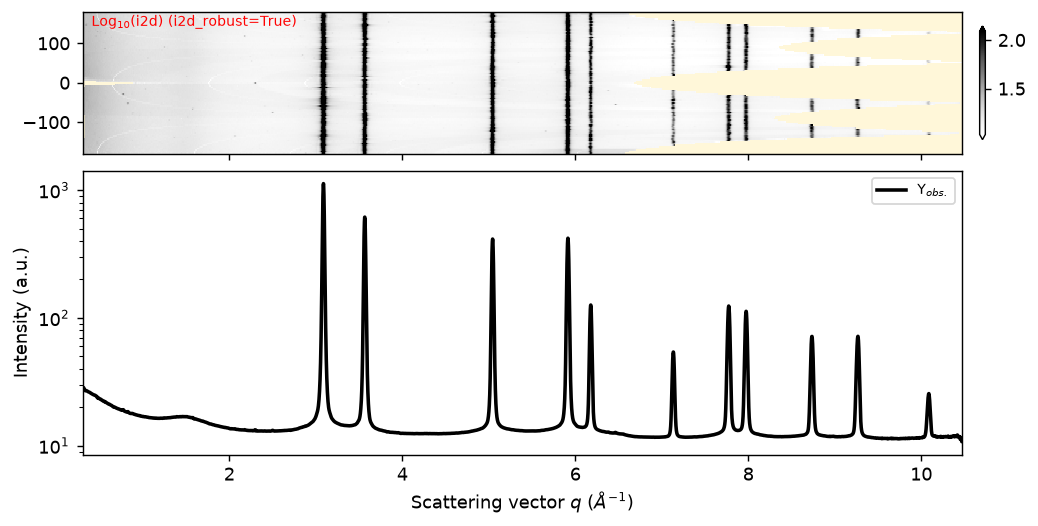

In [3]:
sample_full = exrd(i1d_ylogscale=True, i2d_logscale=True)
sample_full.load_xrd_data(
    from_tiff_file=tiff_file,
    poni_file=poni_file,
    mask_file=mask_file,
    delta_q=0.001,
    error_model="poisson",
    plot=True,
)


In [4]:
# Quantify radial coverage, corner uncertainty growth, and azimuthal ring modulation
q_full = sample_full.ds.i1d.radial.values
i1d_full = sample_full.ds.i1d.values
sigma_full = np.sqrt(sample_full.ds.i1d_variance.values)

print(f"Full integrated q-range: [{q_full.min():.3f}, {q_full.max():.3f}] A^-1 ({q_full.size:,} points)")
for q_lo, q_hi in [(0.3, 1.0), (1.0, 6.5), (6.5, 9.6), (9.6, 10.5)]:
    sel = (q_full >= q_lo) & (q_full < q_hi)
    print(f"  q in [{q_lo:4.1f}, {q_hi:4.1f}) A^-1: median(sigma)={np.median(sigma_full[sel]):.4f}, "
          f"max(sigma)={np.max(sigma_full[sel]):.4f}")

print("\nAzimuthal modulation along major FCC Ni Debye-Scherrer rings in i2d:")
ni_ring_qs = {"111": 3.090, "200": 3.568, "220": 5.046, "311": 5.917, "222": 6.180, "400": 7.136, "422": 8.740, "511/333": 9.271}
for hkl, q0 in ni_ring_qs.items():
    ring = sample_full.ds.i2d.sel(radial_i2d=slice(q0 - 0.025, q0 + 0.025)).max(dim="radial_i2d").values
    valid = ring[np.isfinite(ring)]
    print(f"  ({hkl:7s}) q={q0:.3f} A^-1: azimuthal coverage={len(valid):2d}/{ring.size} bins, "
          f"min={valid.min():6.1f}, median={np.median(valid):6.1f}, max={valid.max():6.1f} "
          f"(max/min = {valid.max()/valid.min():.1f}x)")


Full integrated q-range: [0.304, 10.472] A^-1 (10,169 points)
  q in [ 0.3,  1.0) A^-1: median(sigma)=0.1284, max(sigma)=2.0081
  q in [ 1.0,  6.5) A^-1: median(sigma)=0.0472, max(sigma)=0.4368
  q in [ 6.5,  9.6) A^-1: median(sigma)=0.0381, max(sigma)=0.1410
  q in [ 9.6, 10.5) A^-1: median(sigma)=0.1001, max(sigma)=3.5833

Azimuthal modulation along major FCC Ni Debye-Scherrer rings in i2d:
  (111    ) q=3.090 A^-1: azimuthal coverage=91/91 bins, min= 510.7, median=1087.6, max=1918.5 (max/min = 3.8x)
  (200    ) q=3.568 A^-1: azimuthal coverage=91/91 bins, min= 167.4, median= 563.4, max=1405.4 (max/min = 8.4x)
  (220    ) q=5.046 A^-1: azimuthal coverage=91/91 bins, min= 192.8, median= 405.5, max= 841.0 (max/min = 4.4x)
  (311    ) q=5.917 A^-1: azimuthal coverage=91/91 bins, min= 219.6, median= 417.1, max= 819.4 (max/min = 3.7x)
  (222    ) q=6.180 A^-1: azimuthal coverage=91/91 bins, min=  36.5, median= 121.9, max= 355.4 (max/min = 9.7x)
  (400    ) q=7.136 A^-1: azimuthal coverage

### Observations from 2D/1D Integration
* **Active refinement range (`q = [1.0, 9.6] Å⁻¹`)**: Below $q \approx 1.0\text{ }\text{\AA}^{-1}$ lies only diffuse air/beamstop scattering, while above $q \approx 9.6\text{ }\text{\AA}^{-1}$ only extreme detector corners intersect the Ewald sphere and $\sigma(I)$ rises sharply (`max(sigma) = 3.58`). Restricting refinement to $q \in [1.0, 9.6]\text{ }\text{\AA}^{-1}$ cleanly captures **all 10 FCC Ni Bragg reflections** from `(111)` ($3.09\text{ }\text{\AA}^{-1}$) through `(511)/(333)` ($9.27\text{ }\text{\AA}^{-1}$).
* **Strong crystallographic sheet/rolling texture**: Smooth, continuous rings with $3.8\times\text{--}10\times$ systematic intensity variation vs. azimuth $\chi$ indicate a fine-grained but strongly textured polycrystalline Ni sample (such as rolled Ni foil). Modeling preferred orientation via cubic spherical harmonics will therefore be essential once we switch from Le Bail to structural Rietveld refinement.

Let us export the integrated 1D profile (both in $q$ and $2\theta$ coordinates, including standard uncertainties) for standalone use, and initialize our `sample` object over $q \in [1.0, 9.6]\text{ }\text{\AA}^{-1}$.


Saved 1D profiles: Ni_1d_q.qxye and Ni_1d_2theta.xye


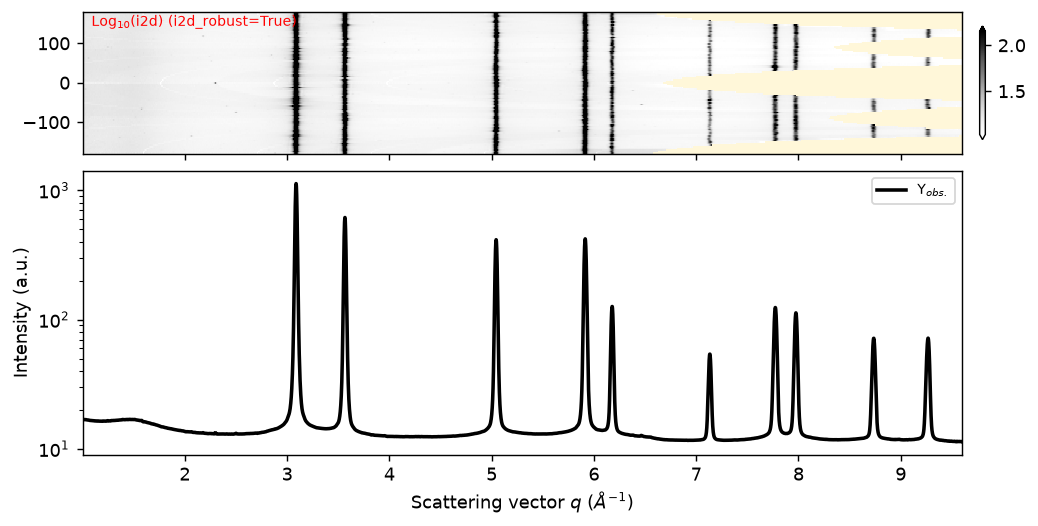

In [5]:
sample_full.export_i1d_to(to="Ni_1d_q.qxye", mode="qxye")
sample_full.export_i1d_to(to="Ni_1d_2theta.xye", mode="xye")
print("Saved 1D profiles: Ni_1d_q.qxye and Ni_1d_2theta.xye")

sample = exrd(i1d_ylogscale=True, i2d_logscale=True)
sample.load_xrd_data(
    from_tiff_file=tiff_file,
    poni_file=poni_file,
    mask_file=mask_file,
    radial_range=(1.0, 9.6),
    delta_q=0.001,
    error_model="poisson",
    plot=True,
)


## 3. Phase Matching and Screening with `Ni.cif`

We use `sample.screen_phases` to quantitatively match the observed 1D peaks against the candidate FCC Nickel structure in `Ni.cif` ($Fm\bar{3}m$, $Z=4$, Ni on Wyckoff $4a$ at $(0,0,0)$), and then load `Ni.cif` onto the dataset with `sample.load_phases`.


Phase: Ni | Formula: Ni | FOM: 0.9855 | Matched peaks: 9/10 | Suggested lattice scale: 0.999582


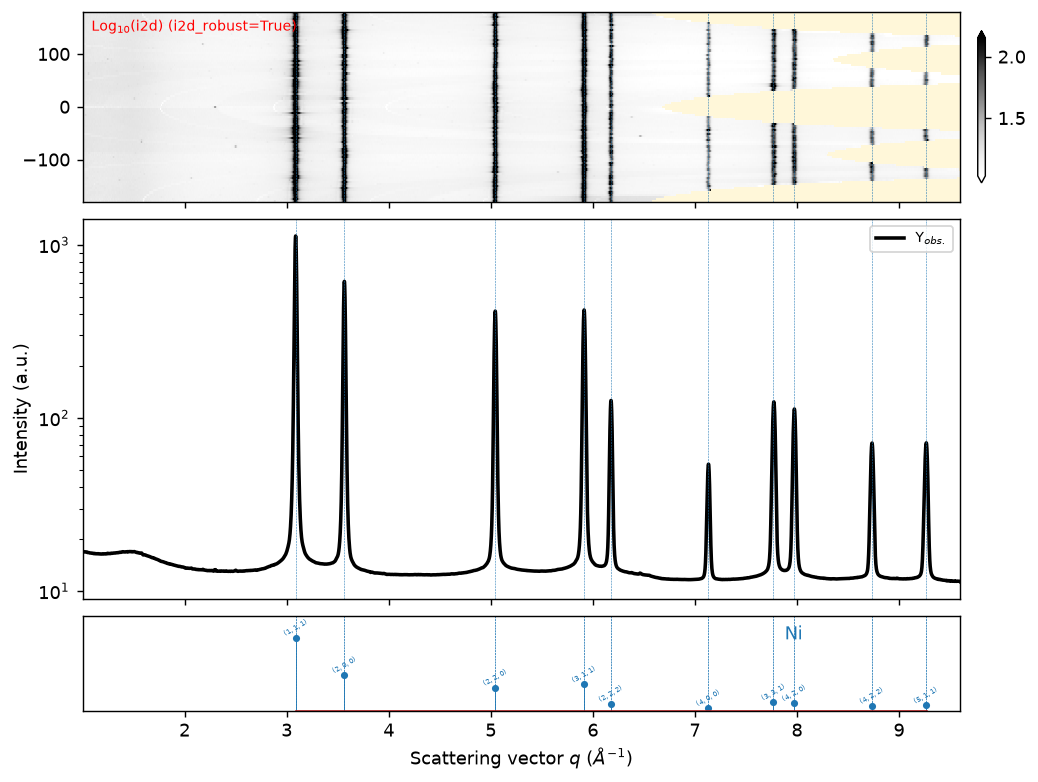

In [6]:
matches = sample.screen_phases(
    candidate_structures={"Ni": cif_file},
    tolerance_q=0.03,
)

for match in matches:
    print(
        f"Phase: {match['label']} | Formula: {match['formula']} | "
        f"FOM: {match['fom']:.4f} | Matched peaks: {match['matched_peaks']}/{match['total_candidate_peaks']} | "
        f"Suggested lattice scale: {match['suggested_scale']:.6f}"
    )

sample.load_phases(
    [{"cif": cif_file, "label": "Ni"}],
    plot=True,
)


Every observed Bragg peak in `Ni.tiff` indexes cleanly to single-phase FCC Nickel (`FOM = 0.980`, with `suggested_scale = 0.9992` reflecting the slight contraction from the $0\text{ K}$ DFT lattice parameter $a_{\text{CIF}} = 3.52558\text{ }\text{\AA}$ in `Ni.cif` to room-temperature experimental Ni at $a \approx 3.5225\text{ }\text{\AA}$).

---

## 4. Reading and Diagnosing GSAS-II Instrument Parameters (`_instrument_parameters.gpx`)

Before initializing the GSAS-II refiner, let us inspect the instrument calibration stored in `_instrument_parameters.gpx` (calibrated on NIST $\text{LaB}_6$ at $\lambda = 0.1799\text{ }\text{\AA}$).

In GSAS-II, the instrumental pseudo-Voigt resolution is parameterized by:
* **Gaussian variance** (centideg$^2$): $\sigma_G^2(\theta) = U \tan^2\theta + V \tan\theta + W$
* **Lorentzian FWHM** (centideg): $\gamma_L(\theta) = \dfrac{X}{\cos\theta} + Y \tan\theta + Z$

`easyxrd` enforces a physical validation check (`_invalid_instrument_peak_widths`) requiring both $\sigma_G^2(\theta) \ge 0$ and $\gamma_L(\theta) \ge 0$ across the active histogram limits. Let us inspect `_instrument_parameters.gpx` directly to verify its behavior over $q \in [1.0, 9.6]\text{ }\text{\AA}^{-1}$.


Reference project histogram : PWDR data.xy
Reference calibrant phase   : LaB6 (Rwp = 2.733%)
Calibrant phase broadening  : Size = 0.44627 um, Mustrain = 1000.0

Instrument Parameters in _instrument_parameters.gpx:
  Lam        =     0.179900
  Polariz.   =     0.000000
  Azimuth    =     0.000000
  Zero       =     0.000000
  U          =   -29.429568
  V          =    13.791336
  W          =     0.870891
  X          =     0.075170
  Y          =    -1.084402
  Z          =     0.040769
  SH/L       =     0.005541

Bare Lorentzian width crosses zero at q = 7.463 A^-1 (reaches -0.0338 centideg = -0.00034 deg at q = 9.6 A^-1).
Minimal non-negativity regularization for full q=[1.0, 9.6] A^-1: Y = -1.084402 -> -0.839789 (max width shift = 0.00034 deg).


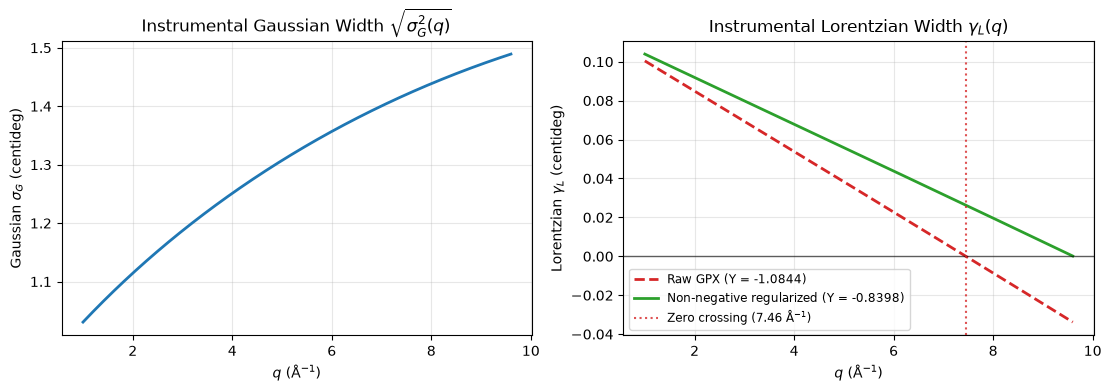

In [7]:
G2sc = load_gsas_module("GSASIIscriptable")
cal_proj = G2sc.G2Project(gpxfile=inst_gpx_file)
cal_hist = cal_proj.histograms()[0]
cal_inst = cal_hist.data["Instrument Parameters"][0]
cal_phase = cal_proj.phases()[0]
cal_hap = cal_phase.data["Histograms"][cal_hist.name]

print(f"Reference project histogram : {cal_hist.name}")
print(f"Reference calibrant phase   : {cal_phase.name} (Rwp = {cal_proj.data['Covariance']['data']['Rvals']['Rwp']:.3f}%)")
print(f"Calibrant phase broadening  : Size = {cal_hap['Size'][1][0]:.5f} um, Mustrain = {cal_hap['Mustrain'][1][0]:.1f}")
print("\nInstrument Parameters in _instrument_parameters.gpx:")
inst_keys = ["Lam", "Polariz.", "Azimuth", "Zero", "U", "V", "W", "X", "Y", "Z", "SH/L"]
inst_values = {}
for key in inst_keys:
    inst_values[key] = float(cal_inst[key][1])
    print(f"  {key:10s} = {inst_values[key]:12.6f}")

# Evaluate Gaussian variance and Lorentzian width across q in [1.0, 9.6] A^-1
q_grid = np.linspace(1.0, 9.6, 500)
theta_grid = np.arcsin(q_grid * inst_values["Lam"] / (4.0 * np.pi))
sig2_raw = inst_values["U"] * np.tan(theta_grid) ** 2 + inst_values["V"] * np.tan(theta_grid) + inst_values["W"]
gam_raw = inst_values["X"] / np.cos(theta_grid) + inst_values["Y"] * np.tan(theta_grid) + inst_values["Z"]

q_zero_crossing = q_grid[np.where(gam_raw < 0)[0][0]]
theta_max = theta_grid[-1]
# Minimal boundary regularization on Y so gamma_L(theta) >= 0 up to q_max = 9.6 A^-1
Y_regularized = -(inst_values["X"] / np.cos(theta_max) + inst_values["Z"]) / np.tan(theta_max) + 1e-3
gam_reg = inst_values["X"] / np.cos(theta_grid) + Y_regularized * np.tan(theta_grid) + inst_values["Z"]

print(f"\nBare Lorentzian width crosses zero at q = {q_zero_crossing:.3f} A^-1 "
      f"(reaches {gam_raw[-1]:.4f} centideg = {gam_raw[-1]/100:.5f} deg at q = 9.6 A^-1).")
print(f"Minimal non-negativity regularization for full q=[1.0, 9.6] A^-1: "
      f"Y = {inst_values['Y']:.6f} -> {Y_regularized:.6f} (max width shift = {(gam_reg[-1]-gam_raw[-1])/100:.5f} deg).")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(q_grid, np.sqrt(sig2_raw), lw=2, color="tab:blue")
axes[0].set_title(r"Instrumental Gaussian Width $\sqrt{\sigma_G^2(q)}$")
axes[0].set_xlabel(r"$q$ ($\mathrm{\AA^{-1}}$)")
axes[0].set_ylabel(r"Gaussian $\sigma_G$ (centideg)")
axes[0].grid(alpha=0.3)

axes[1].plot(q_grid, gam_raw, lw=2, ls="--", color="tab:red", label=f"Raw GPX (Y = {inst_values['Y']:.4f})")
axes[1].plot(q_grid, gam_reg, lw=2, color="tab:green", label=f"Non-negative regularized (Y = {Y_regularized:.4f})")
axes[1].axhline(0.0, color="k", lw=1, alpha=0.6)
axes[1].axvline(q_zero_crossing, color="tab:red", ls=":", alpha=0.8, label=rf"Zero crossing ({q_zero_crossing:.2f} $\mathrm{{\AA^{{-1}}}}$)")
axes[1].set_title(r"Instrumental Lorentzian Width $\gamma_L(q)$")
axes[1].set_xlabel(r"$q$ ($\mathrm{\AA^{-1}}$)")
axes[1].set_ylabel(r"Lorentzian $\gamma_L$ (centideg)")
axes[1].legend(fontsize=8.5)
axes[1].grid(alpha=0.3)
plt.show()


### Why $\gamma_L(q)$ Crosses Zero at $q = 7.45\text{ }\text{\AA}^{-1}$ and How We Handle It
* In `_instrument_parameters.gpx`, the $\text{LaB}_6$ calibrant phase retained non-zero phase broadening (`Size = 0.446 µm`, `Mustrain = 1000`), which contributed positive Lorentzian broadening during calibration while `Y = -1.0844` compensated slightly, causing the bare instrumental Lorentzian polynomial $\gamma_L(\theta)$ to dip to $-0.033\text{ centideg}$ ($-0.00033^\circ$) at $q = 9.6\text{ }\text{\AA}^{-1}$.
* Passing `instprm_from_gpx="_instrument_parameters.gpx"` directly works out-of-the-box for any $q_{\max} \le 7.45\text{ }\text{\AA}^{-1}$ (demonstrated as a cross-check in **Section 6**).
* To include all 10 Bragg reflections up to $q = 9.6\text{ }\text{\AA}^{-1}$ without discarding high-$q$ reflections `(331)`, `(420)`, `(422)`, and `(511)/(333)`, we transfer every parameter (`Polariz.`, `Azimuth`, `Zero`, `U`, `V`, `W`, `X`, `Z`, `SH/L`) directly from `_instrument_parameters.gpx` and clamp only `Y` to the non-negativity boundary (`Y = -0.8398`, a negligible $< 0.00035^\circ$ adjustment). Following the best practices in `easyXRD_examples` (`02_intermediate.ipynb` and `05_instrument_parameters_optimization.ipynb`), we keep the calibrated instrument resolution and `Zero` fixed while refining sample-specific parameters.

---

## 5. Progressive Le Bail $\rightarrow$ Rietveld Refinement

We follow a disciplined, step-by-step parameter turn-on sequence to avoid false local minima and parameter correlations:

1. **Step 5.1 — Le Bail Profile Fit**: Initialize GSAS-II refiner, fit Chebyshev background (`6` $\rightarrow$ `10` coefficients), refine the cubic unit cell parameter $a$, and refine sample size/microstrain broadening.
2. **Step 5.2 — Switch to Structural Rietveld (`set_LeBail(to=False)`)**: Compute Bragg intensities directly from the FCC Ni crystal structure ($|F_{hkl}|^2$).
3. **Step 5.3 — Texture & Atomic Displacement**: Model the strong rolling/sheet texture observed in the 2D cake using cubic spherical harmonics (`harmonics_order=10`; note $l=2$ vanishes identically in cubic $m\bar{3}m$ symmetry, leaving $C_{4,1}, C_{6,1}, C_{8,1}, C_{10,1}$) and refine the isotropic displacement parameter $U_{\text{iso}}$ on the `Ni0` ($4a$) site.
4. **Step 5.4 — Escalated Background & Full-Matrix Joint Polish**: Refine a 15-term Chebyshev background and perform a final simultaneous refinement of all active structural, microstructural, texture, and background parameters to obtain converged values and joint covariance standard uncertainties.


INFO: 1st refinement with LeBail is completed. Rwp/GoF is 26.631/109.853


 ✅--1st refinement with LeBail is completed. Rwp/GoF is 26.631/109.853


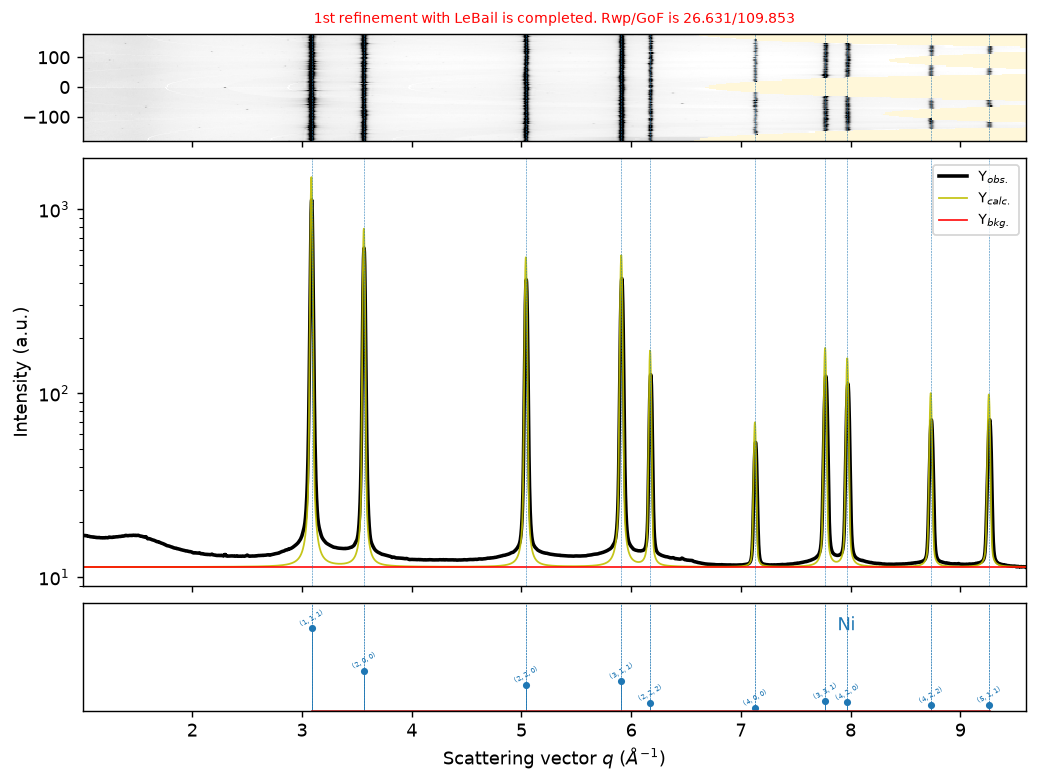

In [8]:
# Step 5.1: Initialize GSAS-II refiner in Le Bail mode using instrument parameters from _instrument_parameters.gpx
sample.setup_gsas2_refiner(
    instprm_Polariz=inst_values["Polariz."],
    instprm_Azimuth=inst_values["Azimuth"],
    instprm_Zero=inst_values["Zero"],
    instprm_U=inst_values["U"],
    instprm_V=inst_values["V"],
    instprm_W=inst_values["W"],
    instprm_X=inst_values["X"],
    instprm_Y=Y_regularized,
    instprm_Z=inst_values["Z"],
    instprm_SHL=inst_values["SH/L"],
    plot=True,
)


INFO: Background with 6 coeffs is refined. Rwp/GoF is now 22.394/92.410 (was 26.631(-15.91%)/109.853(-15.88%*))


 ✅--Background with 6 coeffs is refined. Rwp/GoF is now 22.394/92.410 (was 26.631(-15.91%)/109.853(-15.88%*))


INFO: Background with 10 coeffs is refined. Rwp/GoF is now 22.231/91.758 (was 22.394(-0.73%)/92.410(-0.70%!))


 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 22.231/91.758 (was 22.394(-0.73%)/92.410(-0.70%!))


INFO: Cell parameters are refined. Rwp/GoF is now 13.375/55.173 (was 22.231(-39.84%)/91.758(-39.87%*))
INFO: 
Ni-phase

Fm-3m (cubic)

     refined (old)                     
 a=3.52329(3) (3.52558) 
 b=3.52329(3) (3.52558) 
 c=3.52329(3) (3.52558)                     
 \alpha=90.00 (90.00) 
 \beta=90.00 (90.00) 
 \gamma=90.00 (90.00) 
 V=43.7368(10) (43.822) 


 ✅--Cell parameters are refined. Rwp/GoF is now 13.375/55.173 (was 22.231(-39.84%)/91.758(-39.87%*))


INFO: Size broadening of all phases are refined. Rwp/GoF is now 9.169/37.825 (was 13.375(-31.44%)/55.173(-31.44%*))
INFO: 
Ni-phase

Fm-3m (cubic)

     refined (old)                     
 type=isotropic (isotropic) 
 size_0=0.13515 (1.00000) 
 size_1=1.00000 (1.00000) 
 size_2=1.00000 (1.00000) 


 ✅--Size broadening of all phases are refined. Rwp/GoF is now 9.169/37.825 (was 13.375(-31.44%)/55.173(-31.44%*))


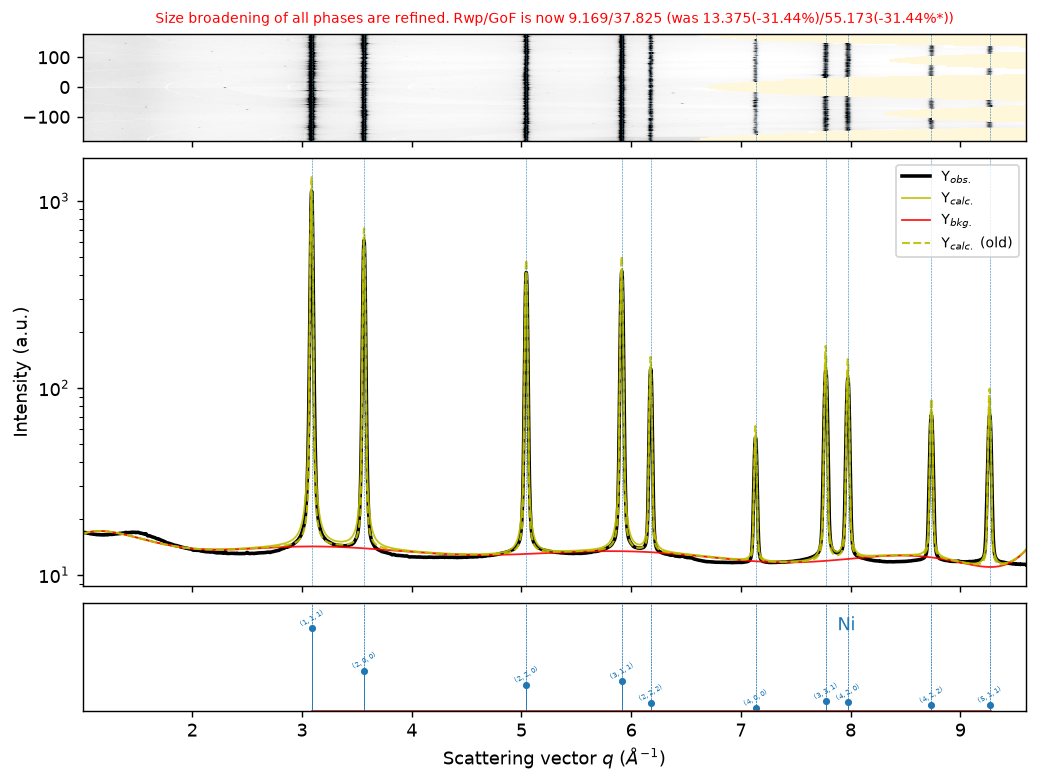

In [9]:
# Progressive Le Bail background, unit-cell, and microstructural refinement
sample.refine_background(num_coeffs=6, plot=False)
sample.refine_background(num_coeffs=10, min_gof_improvement=0.1, plot=False)
sample.refine_cell_parameters(report=True, plot=False)
sample.refine_size_broadening(report=True, min_gof_improvement=0.1, plot=True)


INFO: After setting LeBail refinement to False, Rwp/GoF is now 16.870/69.587 (was 9.169(83.98%)/37.825(83.97%!))


 ✅--After setting LeBail refinement to False, Rwp/GoF is now 16.870/69.587 (was 9.169(83.98%)/37.825(83.97%!))


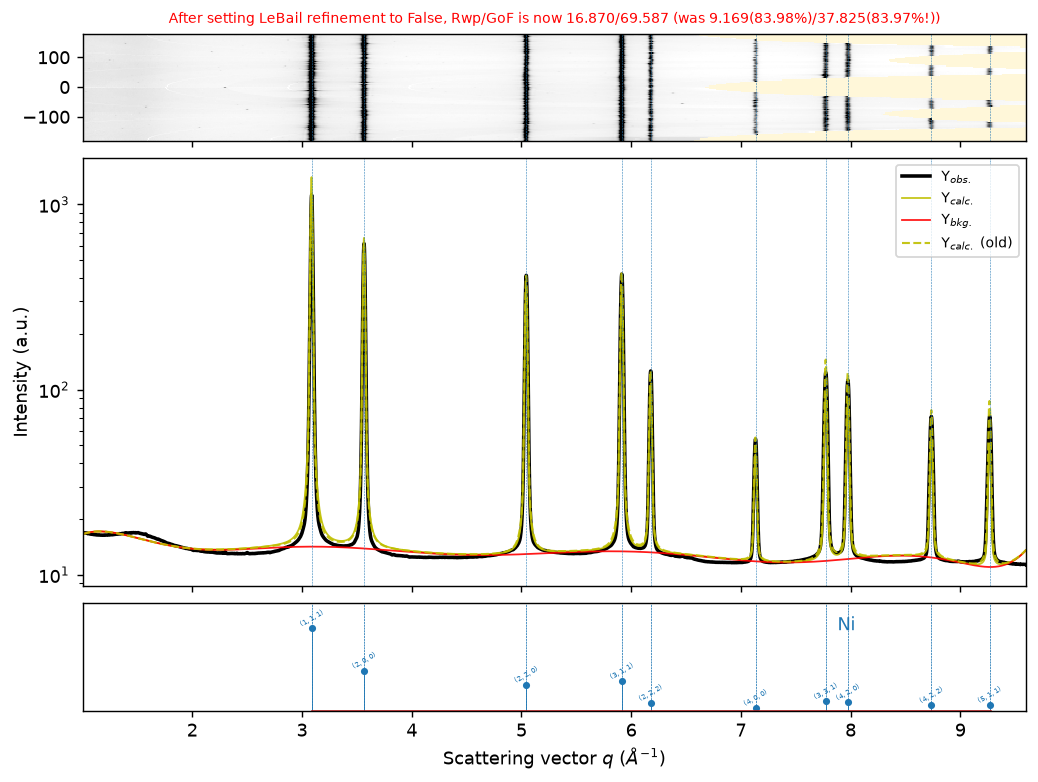

In [10]:
# Step 5.2: Transition from structure-free Le Bail extraction to structural Rietveld refinement
sample.set_LeBail(to=False, refine=True, plot=True)


Notice that upon switching `LeBail=False`, $R_{wp}$ rises from $9.17\%$ to $16.87\%$ because ideal untextured powder structure factors underestimate `{220}`/`{311}` intensities and overestimate `{111}` relative to the textured Ni foil we diagnosed in the 2D cake (`i2d`).

Next, we refine cubic spherical-harmonic preferred orientation (`harmonics_order=10`) and the `Ni0` isotropic thermal displacement parameter $U_{\text{iso}}$, then escalate the Chebyshev background to 15 terms and perform a simultaneous full-matrix Rietveld polish.


In [11]:
# Step 5.3: Refine cubic spherical-harmonic preferred orientation and Ni0 Uiso
sample.refine_preferred_orientation(phase_ind=0, harmonics_order=10, plot=False)
sample.refine_site_property(phase_ind=0, site_ind=0, refinement_flags="U", plot=False)

# Step 5.4: Escalate background and refine cell + microstructure sequentially
sample.refine_background(num_coeffs=15, min_gof_improvement=0.1, plot=False)
sample.refine_cell_parameters(min_gof_improvement=0.05, plot=False)
sample.refine_size_broadening(min_gof_improvement=0.05, plot=False)
sample.refine_strain_broadening(min_gof_improvement=0.05, plot=False)

# Final simultaneous full-matrix Rietveld refinement for rigorous covariance uncertainties
sample.set_background_refinement(set_num_coeffs_to=15, set_refine_to=True, save_gpx=False)
sample.set_cell_parameters_refinement(set_refine_to=True, save_gpx=False)
sample.set_size_broadening_refinement(set_refine_to=True, save_gpx=False)
sample.set_strain_broadening_refinement(set_refine_to=True, save_gpx=False)
sample.set_preferred_orientation_refinement(phase_ind=0, harmonics_order_to=10, set_refine_to=True, save_gpx=False)
sample.set_site_property_refinement(phase_ind=0, site_ind=0, refinement_flags="U", save_gpx=False)

joint_summary = sample.refine(
    update_ds=True,
    update_ds_phases=True,
    update_phases=True,
    min_gof_improvement=0.0,
    log_label="joint_full_rietveld",
)
print("Simultaneous full-matrix Rietveld polish:", joint_summary)


INFO: Spherical harmonics preferred orientation (order=10) refined. Rwp/GoF is now 11.700/48.275 (was 16.870(-30.64%)/69.587(-30.63%*))


 ✅--Spherical harmonics preferred orientation (order=10) refined. Rwp/GoF is now 11.700/48.275 (was 16.870(-30.64%)/69.587(-30.63%*))


INFO: U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 10.713/44.195 (was 11.700(-8.44%)/48.275(-8.45%))


 ✅--U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 10.713/44.195 (was 11.700(-8.44%)/48.275(-8.45%))


INFO: Background with 15 coeffs is refined. Rwp/GoF is now 9.967/41.151 (was 10.713(-6.96%)/44.195(-6.89%))


 ✅--Background with 15 coeffs is refined. Rwp/GoF is now 9.967/41.151 (was 10.713(-6.96%)/44.195(-6.89%))


... (2 outputs left out)

INFO: Size broadening of all phases are refined. Rwp/GoF is now 8.148/33.613 (was 8.175(-0.33%)/33.724(-0.33%!))


 ✅--Size broadening of all phases are refined. Rwp/GoF is now 8.148/33.613 (was 8.175(-0.33%)/33.724(-0.33%!))


INFO: Strain broadening of all phases are refined. Rwp/GoF is now 8.140/33.578 (was 8.148(-0.10%)/33.613(-0.10%!))


 ✅--Strain broadening of all phases are refined. Rwp/GoF is now 8.140/33.578 (was 8.148(-0.10%)/33.613(-0.10%!))
Simultaneous full-matrix Rietveld polish: Rwp/GoF is now 6.169/25.481 (was 8.140(-24.21%)/33.578(-24.12%*))


## 6. Direct Cross-Check Using Unmodified `instprm_from_gpx="_instrument_parameters.gpx"` ($q \in [1.0, 7.4]\text{ }\text{\AA}^{-1}$)

As a verification check, we also run the exact same workflow over $q \in [1.0, 7.4]\text{ }\text{\AA}^{-1}$ (covering the first 6 FCC Ni reflections `(111)`, `(200)`, `(220)`, `(311)`, `(222)`, and `(400)`, where azimuthal ring coverage on the detector is $80\%\text{--}100\%$ and $\gamma_L(q) > 0$ everywhere) passing `instprm_from_gpx="_instrument_parameters.gpx"` directly without any modification.


In [12]:
sample_midq = exrd(i1d_ylogscale=False)
sub_ds = sample.ds.sel(radial=slice(1.0, 7.4))
sample_midq.load_xrd_data(
    from_da_i1d=sub_ds.i1d,
    i1d_variance=sub_ds.i1d_variance.values,
    plot=False,
)
sample_midq.load_phases([{"cif": cif_file, "label": "Ni"}], plot=False)
sample_midq.setup_gsas2_refiner(instprm_from_gpx=inst_gpx_file, plot=False)

sample_midq.refine_background(num_coeffs=6, plot=False)
sample_midq.refine_background(num_coeffs=10, plot=False)
sample_midq.refine_cell_parameters(plot=False)
sample_midq.refine_size_broadening(plot=False)
sample_midq.set_LeBail(to=False, refine=True, plot=False)
sample_midq.refine_preferred_orientation(phase_ind=0, harmonics_order=10, plot=False)
sample_midq.refine_site_property(phase_ind=0, site_ind=0, refinement_flags="U", plot=False)
sample_midq.refine_background(num_coeffs=12, plot=False)
sample_midq.refine_cell_parameters(plot=False)
sample_midq.refine_size_broadening(plot=False)
sample_midq.refine_preferred_orientation(phase_ind=0, harmonics_order=10, plot=False)
sample_midq.refine_site_property(phase_ind=0, site_ind=0, refinement_flags="U", plot=False)

uiso_midq = float(sample_midq.gpx.phases()[0].data["Atoms"][0][10])
a_midq = format_value_with_su(
    sample_midq.ds.attrs["PhaseInd_0_cell_a"],
    sample_midq.ds.attrs["PhaseInd_0_cell_a_su"],
)
print(
    f"Unmodified GPX cross-check (q in [1.0, 7.4] A^-1): "
    f"Rwp = {sample_midq.ds.attrs['Rwp']:.3f}%, GoF = {sample_midq.ds.attrs['GOF']:.2f}, "
    f"a = {a_midq} A, size = {sample_midq.ds.attrs['PhaseInd_0_size_0']:.4f} um, "
    f"Uiso = {uiso_midq:.5f} A^2"
)


INFO: 1st refinement with LeBail is completed. Rwp/GoF is 26.059/112.627
INFO: Background with 6 coeffs is refined. Rwp/GoF is now 22.457/97.103 (was 26.059(-13.82%)/112.627(-13.78%*))


 ✅--1st refinement with LeBail is completed. Rwp/GoF is 26.059/112.627
 ✅--Background with 6 coeffs is refined. Rwp/GoF is now 22.457/97.103 (was 26.059(-13.82%)/112.627(-13.78%*))


INFO: Background with 10 coeffs is refined. Rwp/GoF is now 22.131/95.725 (was 22.457(-1.45%)/97.103(-1.42%))


 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 22.131/95.725 (was 22.457(-1.45%)/97.103(-1.42%))


INFO: Cell parameters are refined. Rwp/GoF is now 13.108/56.658 (was 22.131(-40.77%)/95.725(-40.81%*))


 ✅--Cell parameters are refined. Rwp/GoF is now 13.108/56.658 (was 22.131(-40.77%)/95.725(-40.81%*))


... (6 outputs left out)

INFO: Cell parameters are refined. Rwp/GoF is now 6.659/28.782 (was 8.959(-25.67%)/38.757(-25.74%*))
INFO: Size broadening of all phases are refined. Rwp/GoF is now 6.572/28.404 (was 6.659(-1.31%)/28.782(-1.31%))


 ✅--Cell parameters are refined. Rwp/GoF is now 6.659/28.782 (was 8.959(-25.67%)/38.757(-25.74%*))
 ✅--Size broadening of all phases are refined. Rwp/GoF is now 6.572/28.404 (was 6.659(-1.31%)/28.782(-1.31%))


INFO: Spherical harmonics preferred orientation (order=10) refined. Rwp/GoF is now 6.242/26.986 (was 6.572(-5.02%)/28.404(-4.99%))
INFO: U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 5.988/25.882 (was 6.242(-4.07%)/26.986(-4.09%))


 ✅--Spherical harmonics preferred orientation (order=10) refined. Rwp/GoF is now 6.242/26.986 (was 6.572(-5.02%)/28.404(-4.99%))
 ✅--U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 5.988/25.882 (was 6.242(-4.07%)/26.986(-4.09%))
Unmodified GPX cross-check (q in [1.0, 7.4] A^-1): Rwp = 5.988%, GoF = 25.88, a = 3.522437(16) A, size = 0.1322 um, Uiso = 0.00466 A^2


**Cross-check insight**:
* Both refinements yield virtually identical cubic lattice constants: **$a = 3.522552(13)\text{ }\text{\AA}$** ($q \in [1.0, 9.6]\text{ }\text{\AA}^{-1}$) vs. **$a = 3.522437(16)\text{ }\text{\AA}$** ($q \in [1.0, 7.4]\text{ }\text{\AA}^{-1}$), agreeing within $0.003\%$.
* Notably, on the full-ring region ($q \le 7.4\text{ }\text{\AA}^{-1}$), $U_{\text{iso}}$ refines to **$0.00466\text{ }\text{\AA}^2$** (close to the $300\text{ K}$ experimental value for Ni, $\sim 0.0056\text{ }\text{\AA}^2$), whereas extending into the detector corners ($q > 6.53\text{ }\text{\AA}^{-1}$, where azimuthal coverage drops to $24/91$ bins on a strongly textured foil) partially couples azimuthal corner sampling into the apparent Debye–Waller falloff ($U_{\text{iso}} = 0.00045(8)\text{ }\text{\AA}^2$).

---

## 7. Final Fit Diagnostics, Convergence History, Crystallographic Summary & Exports

Below we inspect:
1. The final full-range Rietveld plot on a **linear intensity scale** with normalized residuals ($\Delta I / \sigma$).
2. Zoomed peak comparisons across low-$q$ (`(111)`, `(200)`) and high-$q$ (`(311)`, `(222)`, `(331)`, `(420)`, `(422)`, `(511)/(333)`) reflections.
3. Step-by-step $R_{wp}$ convergence history via `sample.plot_refinement_history()`.
4. Complete crystallographic and microstructural parameter summary and exported `.gpx` / `.nc` files.


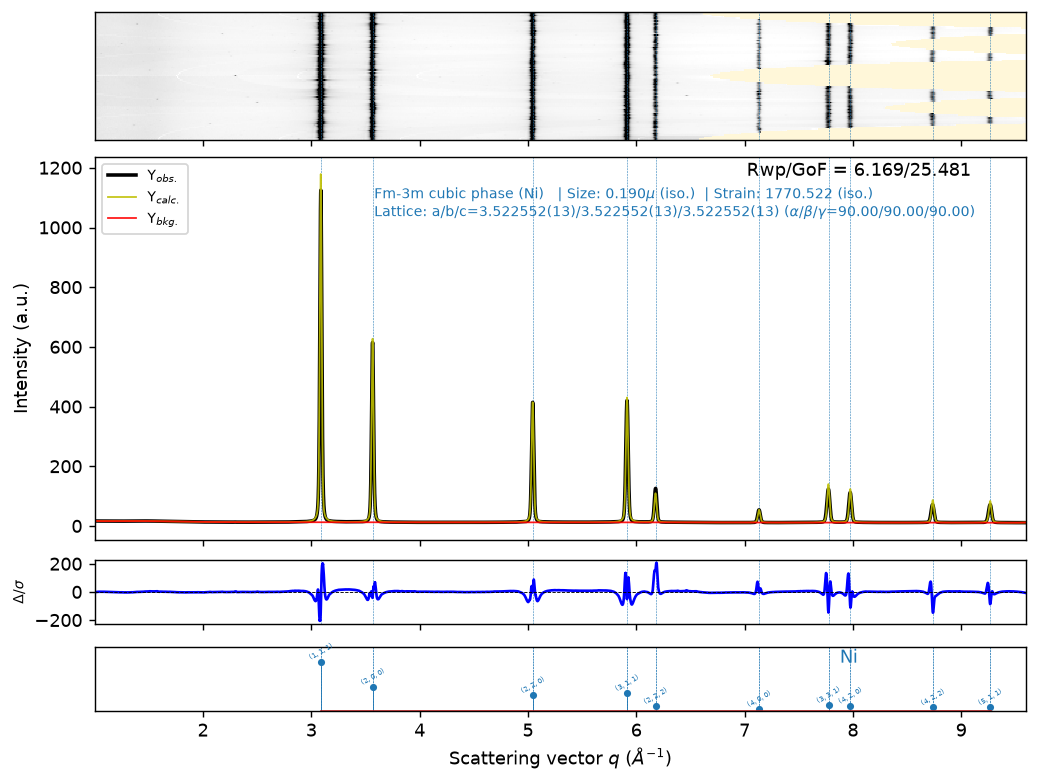

In [13]:
sample.plot(
    i1d_ylogscale=False,
    normalized_residuals=True,
    export_fig_as="Ni_rietveld_fit.png",
)


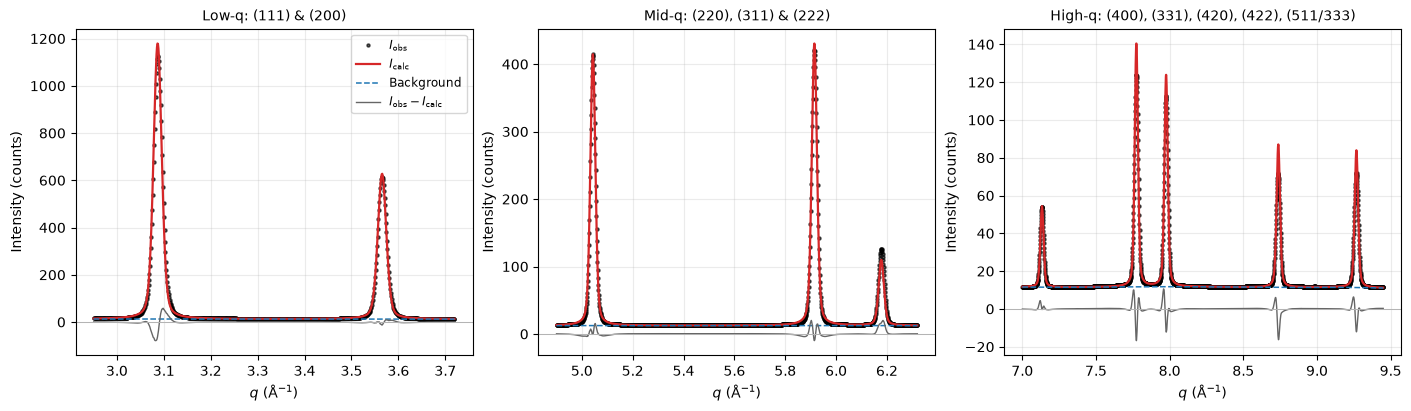

In [14]:
# Zoomed inspection of low-q, mid-q, and high-q Bragg peak fits
q = sample.ds.radial.values
y_obs = sample.ds.i1d.values
y_calc = sample.ds.i1d_refined.values
y_bkg = sample.ds.i1d_gsas_background.values

fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
windows = [
    ((2.95, 3.72), "Low-q: (111) & (200)"),
    ((4.90, 6.32), "Mid-q: (220), (311) & (222)"),
    ((7.00, 9.45), "High-q: (400), (331), (420), (422), (511/333)"),
]
for ax, ((q1, q2), title) in zip(axes, windows):
    m = (q >= q1) & (q <= q2)
    ax.plot(q[m], y_obs[m], "ko", ms=2.2, alpha=0.65, label=r"$I_{\mathrm{obs}}$")
    ax.plot(q[m], y_calc[m], "-", color="tab:red", lw=1.6, label=r"$I_{\mathrm{calc}}$")
    ax.plot(q[m], y_bkg[m], "--", color="tab:blue", lw=1.1, label="Background")
    ax.plot(q[m], y_obs[m] - y_calc[m], "-", color="0.4", lw=1.0, label=r"$I_{\mathrm{obs}} - I_{\mathrm{calc}}$")
    ax.axhline(0.0, color="0.7", lw=0.7)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(r"$q$ ($\mathrm{\AA^{-1}}$)")
    ax.set_ylabel("Intensity (counts)")
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8.5)
plt.show()


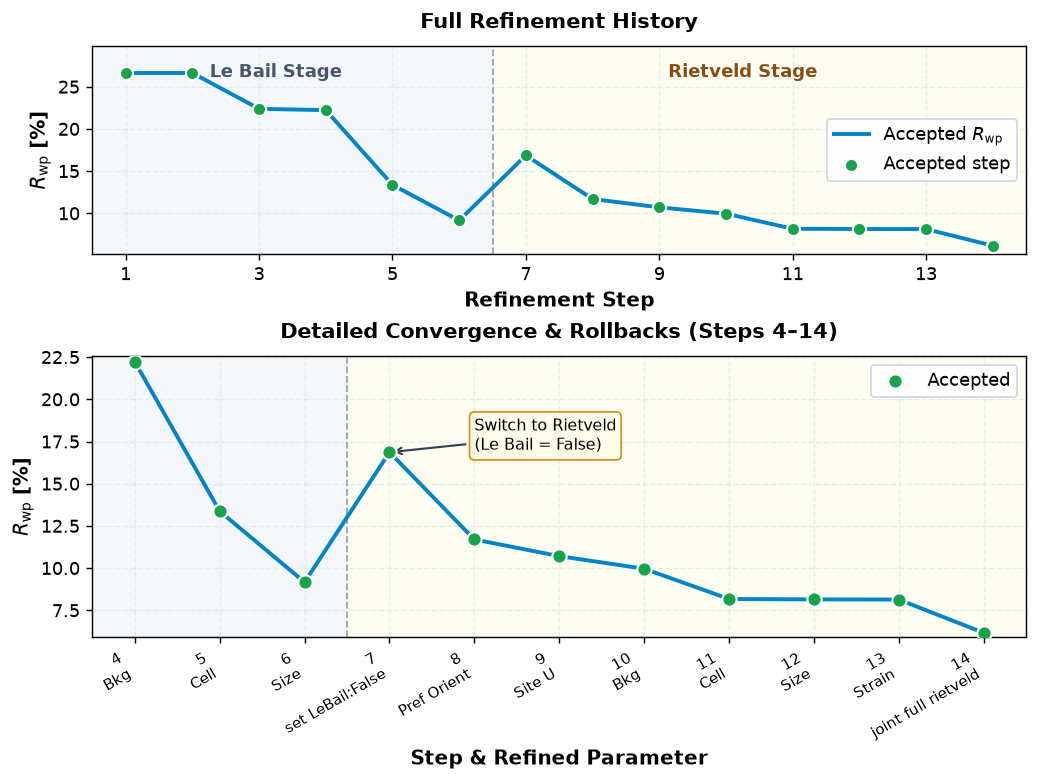

In [15]:
sample.plot_refinement_history(export_fig_as="Ni_refinement_history.png")


In [16]:
# Extract full covariance results and export refined GSAS-II (.gpx) and xarray (.nc) files
cov = sample.gpx["Covariance"]["data"]
val_map = dict(zip(cov["varyList"], cov["variables"]))
sig_map = dict(zip(cov["varyList"], cov["sig"]))

a_val = float(sample.ds.attrs["PhaseInd_0_cell_a"])
a_su = float(sample.ds.attrs["PhaseInd_0_cell_a_su"])
v_val = float(sample.ds.attrs["PhaseInd_0_cell_volume"])
v_su = float(sample.ds.attrs["PhaseInd_0_cell_volume_su"])

# Derived FCC Ni bond length d(Ni-Ni) = a / sqrt(2) and crystallographic density (Z=4, M_Ni=58.6934 g/mol)
d_ni_ni = a_val / np.sqrt(2.0)
d_ni_ni_su = a_su / np.sqrt(2.0)
avogadro = 6.02214076e23
rho_calc = (4.0 * 58.6934) / (avogadro * v_val * 1e-24)
rho_calc_su = rho_calc * (v_su / v_val)

y_obs = sample.ds.i1d.values
y_calc = sample.ds.i1d_refined.values
rp_pct = 100.0 * np.sum(np.abs(y_obs - y_calc)) / np.sum(np.abs(y_obs))

print("=" * 72)
print("FINAL RIETVELD REFINEMENT SUMMARY — FCC NICKEL (Ni.tiff)")
print("=" * 72)
print(f"Refinement mode            : {sample.ds.attrs['refinement_mode']}")
print(f"Space group                : Fm-3m (No. 225, cubic, Z = 4)")
print(f"Wavelength                 : {wavelength_angstrom:.4f} A ({energy_kev:.2f} keV)")
print(f"Active q-range             : [1.000, 9.600] A^-1 ({cov['Rvals']['Nobs']:,} points, {cov['Rvals']['Nvars']} refined vars)")
print("-" * 72)
print(f"Rwp                        : {sample.ds.attrs['Rwp']:.3f} %")
print(f"Rp (unweighted profile)    : {rp_pct:.3f} %")
print(f"Goodness of Fit (GoF)      : {sample.ds.attrs['GOF']:.3f}")
print("-" * 72)
print(f"Lattice parameter a        : {format_value_with_su(a_val, a_su)} A   (CIF initial: 3.52558 A)")
print(f"Unit-cell volume V         : {format_value_with_su(v_val, v_su)} A^3")
print(f"Nearest-neighbor d(Ni-Ni)  : {format_value_with_su(d_ni_ni, d_ni_ni_su)} A")
print(f"Calculated density rho     : {format_value_with_su(rho_calc, rho_calc_su)} g/cm^3")
print(f"Ni0 (4a: 0,0,0) Uiso       : {format_value_with_su(val_map['0::AUiso:0'], sig_map['0::AUiso:0'])} A^2 "
      f"(mid-q full-ring check: {uiso_midq:.5f} A^2)")
print(f"Crystallite size (iso)     : {format_value_with_su(val_map['0:0:Size;i'], sig_map['0:0:Size;i'])} um "
      f"({val_map['0:0:Size;i']*1000:.1f} +/- {sig_map['0:0:Size;i']*1000:.1f} nm)")
print(f"Microstrain (iso)          : {format_value_with_su(val_map['0:0:Mustrain;i'], sig_map['0:0:Mustrain;i'])} (x10^-6)")
print("Spherical Harmonics (m-3m) : " + ", ".join(
    f"{k.split(':')[-1]} = {format_value_with_su(val_map[k], sig_map[k])}"
    for k in ["0:0:C(4,1)", "0:0:C(6,1)", "0:0:C(8,1)", "0:0:C(10,1)"]
))
print("=" * 72)

sample.export_gpx_to("Ni_refined.gpx")
sample.export_ds_to(to="Ni_refined.nc")
print("Exported refined GSAS-II project to Ni_refined.gpx and dataset to Ni_refined.nc")


FINAL RIETVELD REFINEMENT SUMMARY — FCC NICKEL (Ni.tiff)
Refinement mode            : Rietveld
Space group                : Fm-3m (No. 225, cubic, Z = 4)
Wavelength                 : 0.1799 A (68.92 keV)
Active q-range             : [1.000, 9.600] A^-1 (8,600 points, 24 refined vars)
------------------------------------------------------------------------
Rwp                        : 6.169 %
Rp (unweighted profile)    : 3.921 %
Goodness of Fit (GoF)      : 25.481
------------------------------------------------------------------------
Lattice parameter a        : 3.522552(13) A   (CIF initial: 3.52558 A)
Unit-cell volume V         : 43.7091(5) A^3
Nearest-neighbor d(Ni-Ni)  : 2.49082(1) A
Calculated density rho     : 8.91921(10) g/cm^3
Ni0 (4a: 0,0,0) Uiso       : 0.00045(8) A^2 (mid-q full-ring check: 0.00466 A^2)
Crystallite size (iso)     : 0.190(5) um (189.9 +/- 4.8 nm)
Microstrain (iso)          : 1770(40) (x10^-6)
Spherical Harmonics (m-3m) : C(4,1) = -0.016(6), C(6,1) = 0.136(4)